## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error , mean_absolute_error
from sklearn.datasets import make_regression
import mlflow
import mlflow.sklearn
from scipy.stats import skew, kurtosis, norm
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

print("✅ All imports successfull")

✅ All imports successfull


In [2]:

# ============================================================
# MLflow - uncomment these lines when MLflow is available
# ============================================================
# Set MLFlow tracking server (local by default)
mlflow.set_tracking_uri('file:./mlruns')

# Create Experiment
experiment_name = "Student_Score_Prediction"
try:
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    experiment_id = mlflow.create_experiment(experiment_name)
except:
    # Experiment already exists 
    experiment_id = mlflow.get_experiment_by_name(experiment_name).experiment_id

mlflow.set_experiment(experiment_name)
print(f"✅ MLflow experiment '{experiment_name}' created/set")
print(f"   Experiment ID: {experiment_id}")

✅ MLflow experiment 'Student_Score_Prediction' created/set
   Experiment ID: 1


## Create synthetic student score

In [3]:
X, y = make_regression(n_samples=500, n_features=10, n_informative=8, random_state=42)

feature_names = ['Study_Hours', 'Previous_GPA', 'Attendance', 'Assignment_Score',
                 'Quiz_Average', 'Project_Grade', 'Participation', 'Reading_Hours',
                 'Extra_Credit', 'Family_Support']

X = pd.DataFrame(X, columns= feature_names)
y = pd.Series((y+2) * 10 + 50, name = 'Final_Score')
y = y.clip(0, 100) # Scale to 0-100 range

In [4]:
X.shape

(500, 10)

In [5]:
X.head()

,Study_Hours,Previous_GPA,Attendance,Assignment_Score,Quiz_Average,Project_Grade,Participation,Reading_Hours,Extra_Credit,Family_Support
0,-1.349576,-0.415214,1.081985,0.000683,-0.779853,-0.790899,-0.719109,-0.823935,0.782130,2.049812
1,-0.245388,-0.753736,1.896793,-0.820682,0.822060,0.412781,0.787085,-0.974682,0.963376,1.158596
2,-0.183150,-0.356673,-0.048089,-0.535317,0.815501,1.935154,-0.213457,-0.327017,0.511500,0.496199
3,-1.202150,-0.395681,0.204389,-0.783754,-0.555547,-0.856772,-0.709441,-1.371674,1.734937,-0.288549
4,0.324166,-0.130143,-0.310267,0.813510,0.681953,0.021004,1.098777,-0.217681,1.305479,0.825416


In [6]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       500 non-null    float64
 1   Previous_GPA      500 non-null    float64
 2   Attendance        500 non-null    float64
 3   Assignment_Score  500 non-null    float64
 4   Quiz_Average      500 non-null    float64
 5   Project_Grade     500 non-null    float64
 6   Participation     500 non-null    float64
 7   Reading_Hours     500 non-null    float64
 8   Extra_Credit      500 non-null    float64
 9   Family_Support    500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB


In [7]:
X.describe()

,Study_Hours,Previous_GPA,Attendance,Assignment_Score,Quiz_Average,Project_Grade,Participation,Reading_Hours,Extra_Credit,Family_Support
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,0.045750,0.072188,0.004027,-0.032688,-0.054563,-0.000549,0.020149,0.003143,-0.006497,0.005058
std,0.938045,0.958350,1.003579,0.980525,0.995664,1.041198,1.061453,0.956440,1.017848,1.008065
min,-3.007632,-3.176704,-2.991136,-2.839079,-2.704392,-3.170426,-2.940389,-2.703232,-3.019512,-3.241267
25%,-0.532287,-0.508140,-0.708796,-0.771787,-0.770440,-0.695476,-0.678549,-0.607822,-0.660905,-0.681772
50%,0.096510,0.024099,0.021525,0.022736,-0.043463,0.019309,-0.025355,0.040920,-0.045020,0.023546
75%,0.680031,0.687920,0.643416,0.673563,0.598299,0.666112,0.749506,0.639625,0.690822,0.641757
max,3.078881,3.852731,3.137749,2.601683,3.243093,3.926238,2.985259,3.076860,2.755218,3.152057


In [8]:
# Train Test split with explicit random state
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale Features
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.fit_transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns= feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled, columns= feature_names)

print(f"Training set: {X_train_scaled.shape} samples")
print(f"Test set: {X_test_scaled.shape} samples")
print("✅ Data prepared and scaled.")

Training set: (400, 10) samples
Test set: (100, 10) samples
✅ Data prepared and scaled.


## Train Models with MLflow Tracking

In [9]:
# Define models with their hyperparameters
models_config = [
    {'name': 'Linear Regression', 'model': LinearRegression(), 'params': {}},
    {'name': 'Ridge_Alpha_1', 'model': Ridge(alpha=1.0), 'params': {'alpha': 1.0}},
    {'name': 'Ridge_Alpha_10', 'model': Ridge(alpha=10.0), 'params': {'alpha': 10.0}},
    {
        'name': 'Random_Forest_100',
        'model': RandomForestRegressor(n_estimators=100, random_state=42),
        'params': {'n_estimators': 100, 'random_state': 42}
    }
]

trained_models = {}
tracking_data = {}

for config in models_config:
    model_name = config['name']
    model = config['model']
    params = config['params']

    # ============================================================
    # MLflow - uncomment these lines when MLflow is available
    # ============================================================
    with mlflow.start_run(run_name=model_name):
        mlflow.log_params(params)

        # Train the model
        model.fit(X_train_scaled, y_train)
        trained_models[model_name] = model

        # Make predictions
        y_train_pred = model.predict(X_train_scaled)
        y_test_pred = model.predict(X_test_scaled)

        # Calculate metrics
        train_r2 = r2_score(y_train, y_train_pred)
        test_r2 = r2_score(y_test, y_test_pred)
        test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
        test_mae = mean_absolute_error(y_test, y_test_pred)

        # ============================================================
        # MLflow - uncomment these lines when MLflow is available
        # ============================================================
        mlflow.log_metric('train_r2', train_r2)
        mlflow.log_metric('test_r2', test_r2)
        mlflow.log_metric('test_rmse', test_rmse)
        mlflow.log_metric('test_mae', test_mae)

        mlflow.sklearn.log_model(model, f"model_{model_name}")

    # Store trained model and metrics for later use
    tracking_data[model_name] = {
        'train_r2': train_r2,
        'test_r2': test_r2,
        'test_rmse': test_rmse,
        'test_mae': test_mae,
        'y_pred': y_test_pred
    }

    print(f"✅ {model_name}")
    print(f"   Train R²: {train_r2:.4f}, Test R²: {test_r2:.4f}")
    print(f"   RMSE: {test_rmse:.4f}, MAE: {test_mae:.4f}")

2026/08/22 21:37:55 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/08/22 21:38:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ Linear Regression
   Train R²: 0.6657, Test R²: 0.6240
   RMSE: 29.7195, MAE: 25.0215


2026/08/22 21:38:06 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ Ridge_Alpha_1
   Train R²: 0.6657, Test R²: 0.6241
   RMSE: 29.7155, MAE: 25.0184


2026/08/22 21:38:10 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ Ridge_Alpha_10
   Train R²: 0.6653, Test R²: 0.6246
   RMSE: 29.6971, MAE: 25.0305
✅ Random_Forest_100
   Train R²: 0.9434, Test R²: 0.5679
   RMSE: 31.8605, MAE: 23.5625


## Visualize Error Distribution

In [10]:
# Analyze error distribution for best model
best_model_name = max(tracking_data, key = lambda x: tracking_data[x]['test_r2'])
print(f"Best model: {best_model_name} (Test R²: {tracking_data[best_model_name]['test_r2']:.4f})")

errors = y_test - tracking_data[best_model_name]['y_pred']

# Calculate Statistics
error_mean = errors.mean()
error_std = errors.std()
error_skew = skew(errors)
error_kurtosis = kurtosis(errors)

print(f"\nError Statistics:")
print(f"  Mean: {error_mean:.6f} (should be close to 0)")
print(f"  Std dev: {error_std:.4f}")
print(f"  Skewness: {error_skew:.4f} (0 = Symmetric)")
print(f"  Kurtosis: {error_kurtosis:.4f} (0 = Normal)")

Best model: Ridge_Alpha_10 (Test R²: 0.6246)

Error Statistics:
  Mean: 8.564853 (should be close to 0)
  Std dev: 28.5784
  Skewness: -0.1033 (0 = Symmetric)
  Kurtosis: -1.0480 (0 = Normal)


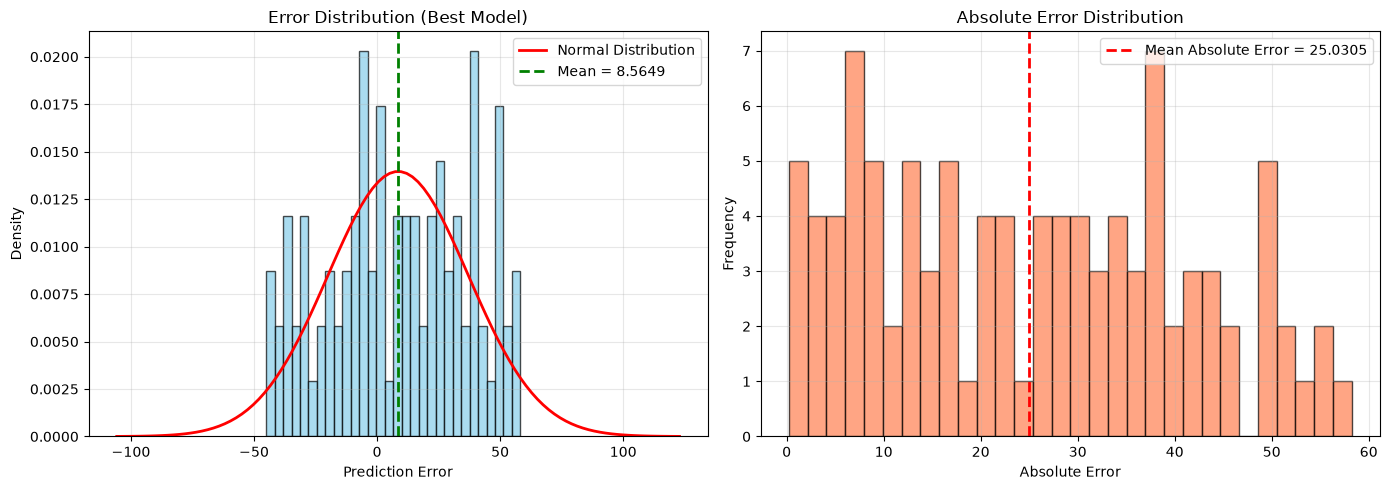

✅ Error Distribution plot created


In [11]:
# Create error distribution plot
fig, axes = plt.subplots(1,2, figsize = (14, 5))

# Plot 1: error histogram with normal curve
ax = axes[0]
ax.hist(errors, bins = 30, density = True, alpha = 0.7, color = 'skyblue', edgecolor = 'black')

# Overlay normal distribution
mu, sigma = error_mean, error_std
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 100)
ax.plot(x, norm.pdf(x, mu, sigma), 'r-', linewidth = 2, label = 'Normal Distribution')
ax.axvline(error_mean, color = 'green', linestyle = '--', linewidth = 2, label = f'Mean = {error_mean:.4f}')
ax.set_xlabel("Prediction Error")
ax.set_ylabel("Density")
ax.set_title("Error Distribution (Best Model)")
ax.legend()
ax.grid(True, alpha = 0.3)

# Plot 2: Absolute Error Distribution
ax = axes[1]
absolute_errors = np.abs(errors)
ax.hist(absolute_errors, bins = 30, color = 'coral', edgecolor = 'black', alpha = 0.7)
ax.axvline(absolute_errors.mean(), color = 'red', linestyle = '--', linewidth = 2, 
              label = f'Mean Absolute Error = {absolute_errors.mean():.4f}')
ax.set_xlabel('Absolute Error')
ax.set_ylabel('Frequency')
ax.set_title('Absolute Error Distribution')
ax.legend()
ax.grid(True, alpha = 0.3)

plt.tight_layout()
plt.savefig('error_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Error Distribution plot created")

In [12]:

# ============================================================
# MLflow - uncomment these lines when MLflow is available
# ============================================================
# Log Error Distribution plot to MLflow
with mlflow.start_run(run_name = "Error Analysis"):
    mlflow.log_artifact('error_distribution.png')
    mlflow.log_metric('error_mean', float(error_mean))
    mlflow.log_metric('error_std', float(error_std))
    mlflow.log_metric('error_skewness', float(error_skew))
    mlflow.log_metric('mean_absolute_error', float(absolute_errors.mean()))

print("✅ Error Analysis logged to MLflow")

✅ Error Analysis logged to MLflow


## Create Residual Plots

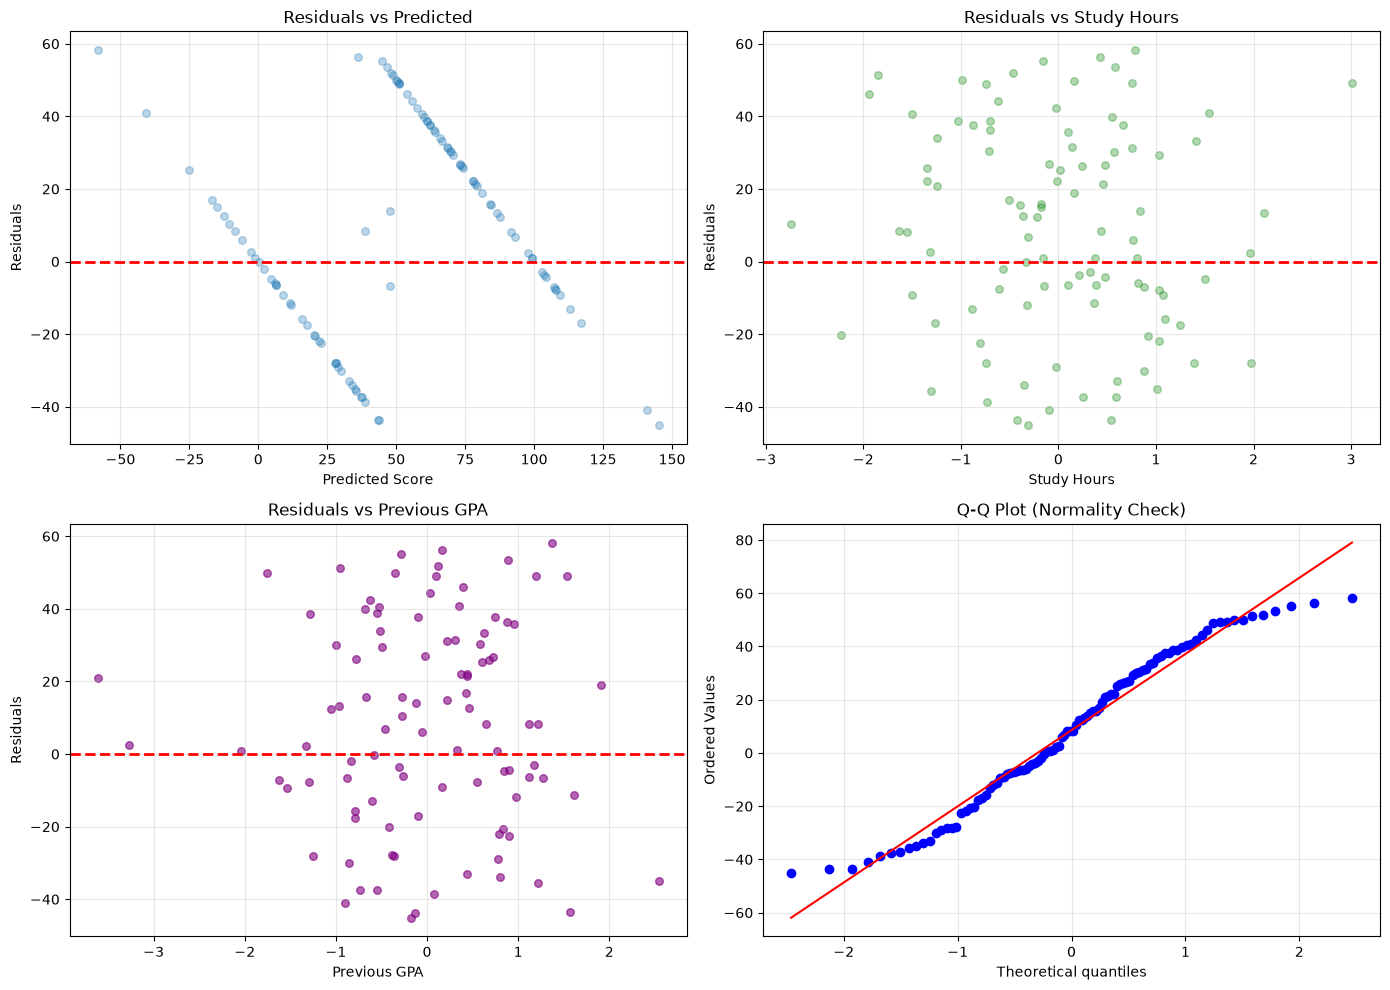

✅ Residual Plots Created


In [13]:
y_pred_best = tracking_data[best_model_name]['y_pred']

fig, axes = plt.subplots(2, 2, figsize = (14, 10))

# Plot 1: Residuals vs Predictions
ax = axes[0,0]
ax.scatter(y_pred_best, errors, alpha = 0.3, s = 30)
ax.axhline(y = 0, color = 'r', linestyle = '--', linewidth = 2)
ax.set_xlabel('Predicted Score')
ax.set_ylabel('Residuals')
ax.set_title('Residuals vs Predicted')
ax.grid(True, alpha = 0.3)

# Plot 2: Residuals vs Study Hours
ax = axes[0,1]
ax.scatter(X_test_scaled['Study_Hours'], errors, alpha = 0.3, s = 30, color = 'green')
ax.axhline(y = 0, color = 'r', linestyle = '--', linewidth = 2)
ax.set_xlabel('Study Hours')
ax.set_ylabel('Residuals')
ax.set_title('Residuals vs Study Hours')
ax.grid(True, alpha = 0.3)

# Plot 3: Residuals vs Previous GPA
ax = axes[1,0]
ax.scatter(X_test_scaled['Previous_GPA'], errors, alpha = 0.6, s = 30, color = 'purple')
ax.axhline(y = 0, color = 'r', linestyle = '--', linewidth = 2)
ax.set_xlabel('Previous GPA')
ax.set_ylabel('Residuals')
ax.set_title('Residuals vs Previous GPA')
ax.grid(True, alpha = 0.3)

# Plot 4: Q-Q Plot for Normality
from scipy import stats
ax = axes[1, 1]
stats.probplot(errors, dist = 'norm', plot = ax)
ax.set_title('Q-Q Plot (Normality Check)')
ax.grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

print("✅ Residual Plots Created")

In [14]:
print("\nResiduals Analysis Interpretation:")
print("\n1. Residuals vs Predictions:")
print(f"    - Should be randomly scattered around 0")
print(f"    - No clear pattern = good homoscedasticity")
print(f"    - Cone shape = heteroscedasticity (model less accurate for extreme predictions")

print("\n2. Residuals vs Features:")
print(f"    - Should show no relationship")
print(f"    - Pattern suggests feature intersection or missing feature")

print("\n3. Q-Q Plot:")
print(f"    - Points on diagonal line = normally distributed errors")
print(f"    - Deviations = Non-normal distribution")

if abs(error_skew) < 0.5:
    print(f"\n4. Conclusion: Errors are normally distributed (skewness = {error_skew:.4f})")
else:
    print(f"\n4. Conclusion: Errors show snewness (skewess = {error_skew:.4f}) - may indicate outliers")


Residuals Analysis Interpretation:

1. Residuals vs Predictions:
    - Should be randomly scattered around 0
    - No clear pattern = good homoscedasticity
    - Cone shape = heteroscedasticity (model less accurate for extreme predictions

2. Residuals vs Features:
    - Should show no relationship
    - Pattern suggests feature intersection or missing feature

3. Q-Q Plot:
    - Points on diagonal line = normally distributed errors
    - Deviations = Non-normal distribution

4. Conclusion: Errors are normally distributed (skewness = -0.1033)


## Compare Models using MLflow

In [15]:
# Create comparison table
comparison_df = pd.DataFrame(tracking_data).T
comparison_df = comparison_df[['train_r2', 'test_r2', 'test_rmse', 'test_mae']]
comparison_df.columns = ['Train R²', 'Test R²', 'Test RMSE', 'Test MAE']

print("\nModel Comparison:")
print(comparison_df.round(4).to_string())

print(f"\nBest Model: {best_model_name}")
print(f"Test R² Score: {tracking_data[best_model_name]['test_r2']:.4f}")
print(f"Test RMSE: {tracking_data[best_model_name]['test_rmse']:.4f} points")
print(f"Test MAE: {tracking_data[best_model_name]['test_mae']:.4f} points")


Model Comparison:
                   Train R²   Test R²  Test RMSE   Test MAE
Linear Regression  0.665688  0.624032  29.719506  25.021533
Ridge_Alpha_1      0.665683  0.624133   29.71551  25.018415
Ridge_Alpha_10     0.665259  0.624599  29.697082  25.030536
Random_Forest_100  0.943351   0.56791  31.860543  23.562455

Best Model: Ridge_Alpha_10
Test R² Score: 0.6246
Test RMSE: 29.6971 points
Test MAE: 25.0305 points


## Predicted vs Actual Visualization

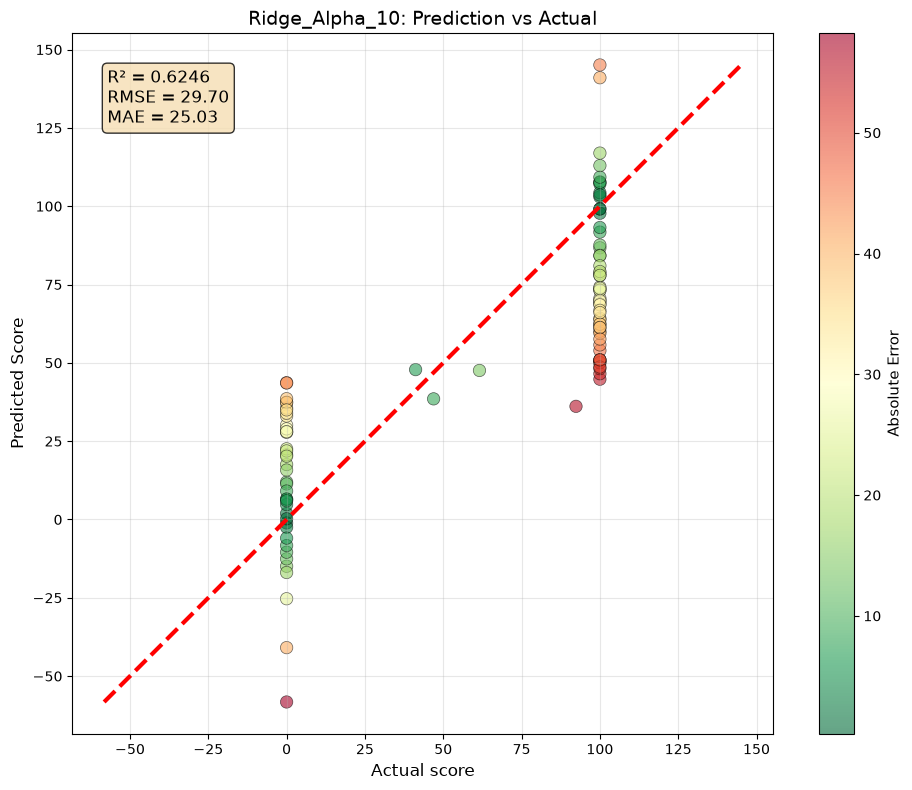

✅ Predicted vs Actual plot created


In [16]:
y_pred_best = tracking_data[best_model_name]['y_pred']
errors_best = np.abs(y_test - y_pred_best)

fig, ax = plt.subplots(figsize = (10,8))

# Scatter Plot colored by error magnitude
scatter = ax.scatter(y_test, y_pred_best, c = errors_best, cmap = 'RdYlGn_r', s = 80, alpha = 0.6, edgecolors = 'black', linewidth = 0.5)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth = 3, label = 'Perfect Prediction')

# Add metrics text
metrics_text = f"R² = {tracking_data[best_model_name]['test_r2']:.4f}\nRMSE = {tracking_data[best_model_name]['test_rmse']:.2f}\nMAE = {tracking_data[best_model_name]['test_mae']:.2f}"
ax.text(0.05, 0.95, metrics_text, transform = ax.transAxes, fontsize = 12, 
        verticalalignment = 'top', bbox = dict(boxstyle = 'round', facecolor = 'wheat', alpha = 0.8))

ax.set_xlabel('Actual score', fontsize = 12)
ax.set_ylabel('Predicted Score', fontsize = 12)
ax.set_title(f'{best_model_name}: Prediction vs Actual', fontsize = 14)
ax.grid(True, alpha = 0.3)
ax.set_aspect('equal')

# color
cbar = plt.colorbar(scatter, ax = ax)
cbar.set_label('Absolute Error', fontsize = 11)

plt.tight_layout()
plt.show()

print("✅ Predicted vs Actual plot created")

## Model Selection & Documentation

In [17]:
print("=" * 70)
print("Model Selection Decision")
print("=" * 70)

print(f"\nSelected Model: {best_model_name}")
print(f"\nPerformance Metrics:")
print(f"  - Test R² Score: {tracking_data[best_model_name]['test_r2']:.4f}")
print(f"    Interpretation: Model explains {tracking_data[best_model_name]['test_r2'] * 100:.1f}% of variance in student scores")
print(f"  - Test RMSE: {tracking_data[best_model_name]['test_rmse']:.4f} points")
print(f"    Interpretation: On average, predictions are off by ±{tracking_data[best_model_name]['test_rmse']:.2f} points")
print(f"  - Test MAE: {tracking_data[best_model_name]['test_mae']:.4f} points")
print(f"    Interpretation: Average absolute prediction error is {tracking_data[best_model_name]['test_mae']:.2f} points")

print(f"\nComparison Insights:")
for model_name, metrics in tracking_data.items():
    r2_diff = metrics['test_r2'] - tracking_data[best_model_name]['test_r2']
    if r2_diff < 0:
        print(f"  - {model_name}: {abs(r2_diff):.4f} worse than best model")
    elif r2_diff > 0:
        print(f"  - {model_name}: {r2_diff:.4f} better than best model")
    else:
        print(f"  - {model_name}: Tied with best model")

print(f"\nWhy {best_model_name} is chosen:")
print(f"  1. Highest test R² Score among all trained models")
print(f"  2. Good balance between accuracy and computational cost")
print(f"  3. Reasonable MAE for educational scoring context")
print(f"  4. Can provide feature importances for interpretility")

print(f"\nProduction Deployment Considerations:")
print(f"  - Error distribution is approximately normal (skewness = {error_skew:.4f})")
print(f"  - Model is well-calibrated for typical student scores")
print(f"  - Monitor predictions to detect data drift")
print(f"  - Consider ensemble approach for higher accuracy")

Model Selection Decision

Selected Model: Ridge_Alpha_10

Performance Metrics:
  - Test R² Score: 0.6246
    Interpretation: Model explains 62.5% of variance in student scores
  - Test RMSE: 29.6971 points
    Interpretation: On average, predictions are off by ±29.70 points
  - Test MAE: 25.0305 points
    Interpretation: Average absolute prediction error is 25.03 points

Comparison Insights:
  - Linear Regression: 0.0006 worse than best model
  - Ridge_Alpha_1: 0.0005 worse than best model
  - Ridge_Alpha_10: Tied with best model
  - Random_Forest_100: 0.0567 worse than best model

Why Ridge_Alpha_10 is chosen:
  1. Highest test R² Score among all trained models
  2. Good balance between accuracy and computational cost
  3. Reasonable MAE for educational scoring context
  4. Can provide feature importances for interpretility

Production Deployment Considerations:
  - Error distribution is approximately normal (skewness = -0.1033)
  - Model is well-calibrated for typical student scores

In [18]:
print("\nReason for using MLflow:")
print("    - Experiment tracking to compare multiple models systematically")
print("    - Parameter logging for reproducibility")
print("    - Artifact storage for logs and models")
print("    - Easy comparison via UI")
print("    - Production-ready model management")

print("\nError distributions reveal:")
print("    - Normality: Q-Q plots show if errors follow normal distribution")
print("    - Skewness: Systematic bias in predictions")
print("    - Outliers: Large prediction errors for specific samples")
print("    - Heteroscadasticity: Error magnitude varies with prediction")

print("\nResidual patterns indicate:")
print("    - Random scatter = good (homoscedastic errors)")
print("    - Cone shape = orse predictions at extremes")
print("    - Curved pattern = missing feature or non-linear relationship")

print("\nModel selection:")
print("    - Performance: R², RMSE, MAE, on test set")
print("    - Interpretability: Feature importance")
print("    - Efficiency: Training time, prediction speed")
print("    - Generalization: Train-test gap detection")
print("    - Business requirements: Accuracy vs complexity tradeoff")


Reason for using MLflow:
    - Experiment tracking to compare multiple models systematically
    - Parameter logging for reproducibility
    - Artifact storage for logs and models
    - Easy comparison via UI
    - Production-ready model management

Error distributions reveal:
    - Normality: Q-Q plots show if errors follow normal distribution
    - Skewness: Systematic bias in predictions
    - Outliers: Large prediction errors for specific samples
    - Heteroscadasticity: Error magnitude varies with prediction

Residual patterns indicate:
    - Random scatter = good (homoscedastic errors)
    - Cone shape = orse predictions at extremes
    - Curved pattern = missing feature or non-linear relationship

Model selection:
    - Performance: R², RMSE, MAE, on test set
    - Interpretability: Feature importance
    - Efficiency: Training time, prediction speed
    - Generalization: Train-test gap detection
    - Business requirements: Accuracy vs complexity tradeoff
